# Machine Learning Mini Project — Phase 3
## Movie Recommendation System

### **Student 1:** Adithya Nayak — **Register number:** 251090700070
### **Student 2:** Shrinidhi Acharya — **Register number:** 251090700077

This notebook loads the fitted model, demonstrates recommendations and checks the Python deployment. Training and model comparison are in the Phase 2 notebook.

**Deployment:** the Python (Flask) application runs locally with `python app.py` (see Section 8).

The default method is selected by validation NDCG@10. A separate supervised model provides personalized recommendations. Current streaming availability is unverified.


## 1 Importing libraries and locating the project

In [1]:
import sys
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
roots = [Path.cwd(), Path.cwd() / 'Movie_Recommendation_Phase3']
ROOT = next((p.resolve() for p in roots if (p/'artifacts/model.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the project folder containing artifacts/model.json.')
sys.path.insert(0, str(ROOT))
from inference import Recommender
engine = Recommender(ROOT/'artifacts/model.json')
print('Fitted model loaded. No training is needed for prediction.')


Fitted model loaded. No training is needed for prediction.


## 2 Checking the fitted artifact
The exported model is fitted on train plus validation data. Test interactions are excluded.

In [2]:
audit=json.loads((ROOT/'artifacts/export_audit.json').read_text())
actual=hashlib.sha256((ROOT/'artifacts/model.json').read_bytes()).hexdigest()
assert actual==audit['model_sha256']
display(pd.DataFrame([audit]))
print('Primary model:',engine.model['primary_model'])
print('Personalized model:',engine.model['personalized_model'])

,model_sha256,ridge_reproduced_test_rmse,fit_ratings,test_ratings_excluded,candidate_movies
0,8224c01dd3f9d743fd41d3d361d286b9e744fddeb802ab...,0.829064,6726,1399,295


Primary model: Popularity
Personalized model: Ridge


## 3 Reviewing model selection
Validation determines the selected method. Test metrics describe final held-out performance.

,Model,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@10,Users
0,Popularity,0.0804,0.3229,0.2063,0.5333,0.1021,270
1,Interaction SVD,0.0622,0.2676,0.1870,0.4444,0.4085,270
2,Ridge,0.0615,0.2541,0.1601,0.4370,0.2042,270
3,Hybrid,0.0552,0.2443,0.1570,0.4296,0.7923,270
4,Gradient Boosting,0.0626,0.2263,0.1438,0.4037,0.2254,270
5,KNN,0.0493,0.1889,0.1271,0.3741,0.5317,270
6,Random Forest,0.0459,0.1779,0.1186,0.3370,0.3028,270
7,Content,0.0378,0.1572,0.1043,0.2963,0.8345,270
8,SVR,0.0396,0.1633,0.1014,0.3074,0.6056,270
9,User CF,0.0344,0.1701,0.0864,0.3000,0.6056,270


,Model,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@10,Users
0,Interaction SVD,0.0891,0.3920,0.2774,0.5969,0.3932,258
1,Popularity,0.0899,0.3529,0.2329,0.5426,0.1288,258
2,Ridge,0.0655,0.2624,0.1745,0.4651,0.2678,258
3,Gradient Boosting,0.0678,0.2636,0.1690,0.4535,0.2542,258
4,KNN,0.0593,0.2363,0.1645,0.4186,0.5661,258
5,Hybrid,0.0609,0.2429,0.1605,0.4147,0.7458,258
6,Random Forest,0.0574,0.2182,0.1464,0.4031,0.4237,258
7,User CF,0.0384,0.1861,0.0971,0.3256,0.5932,258
8,Content,0.0353,0.1419,0.0917,0.2597,0.8271,258
9,SVR,0.0326,0.1306,0.0844,0.2597,0.6373,258


,Model,MAE,RMSE,Training RMSE (in-sample),Rated pairs
0,Ridge,0.6342,0.8291,0.8393,1399
1,Random Forest,0.6359,0.8359,0.5702,1399
2,Gradient Boosting,0.6418,0.8395,0.8239,1399
3,SVR,0.6489,0.8622,0.5089,1399
4,KNN,0.6848,0.8953,0.0749,1399
5,Decision Tree,0.6813,0.9015,0.7728,1399


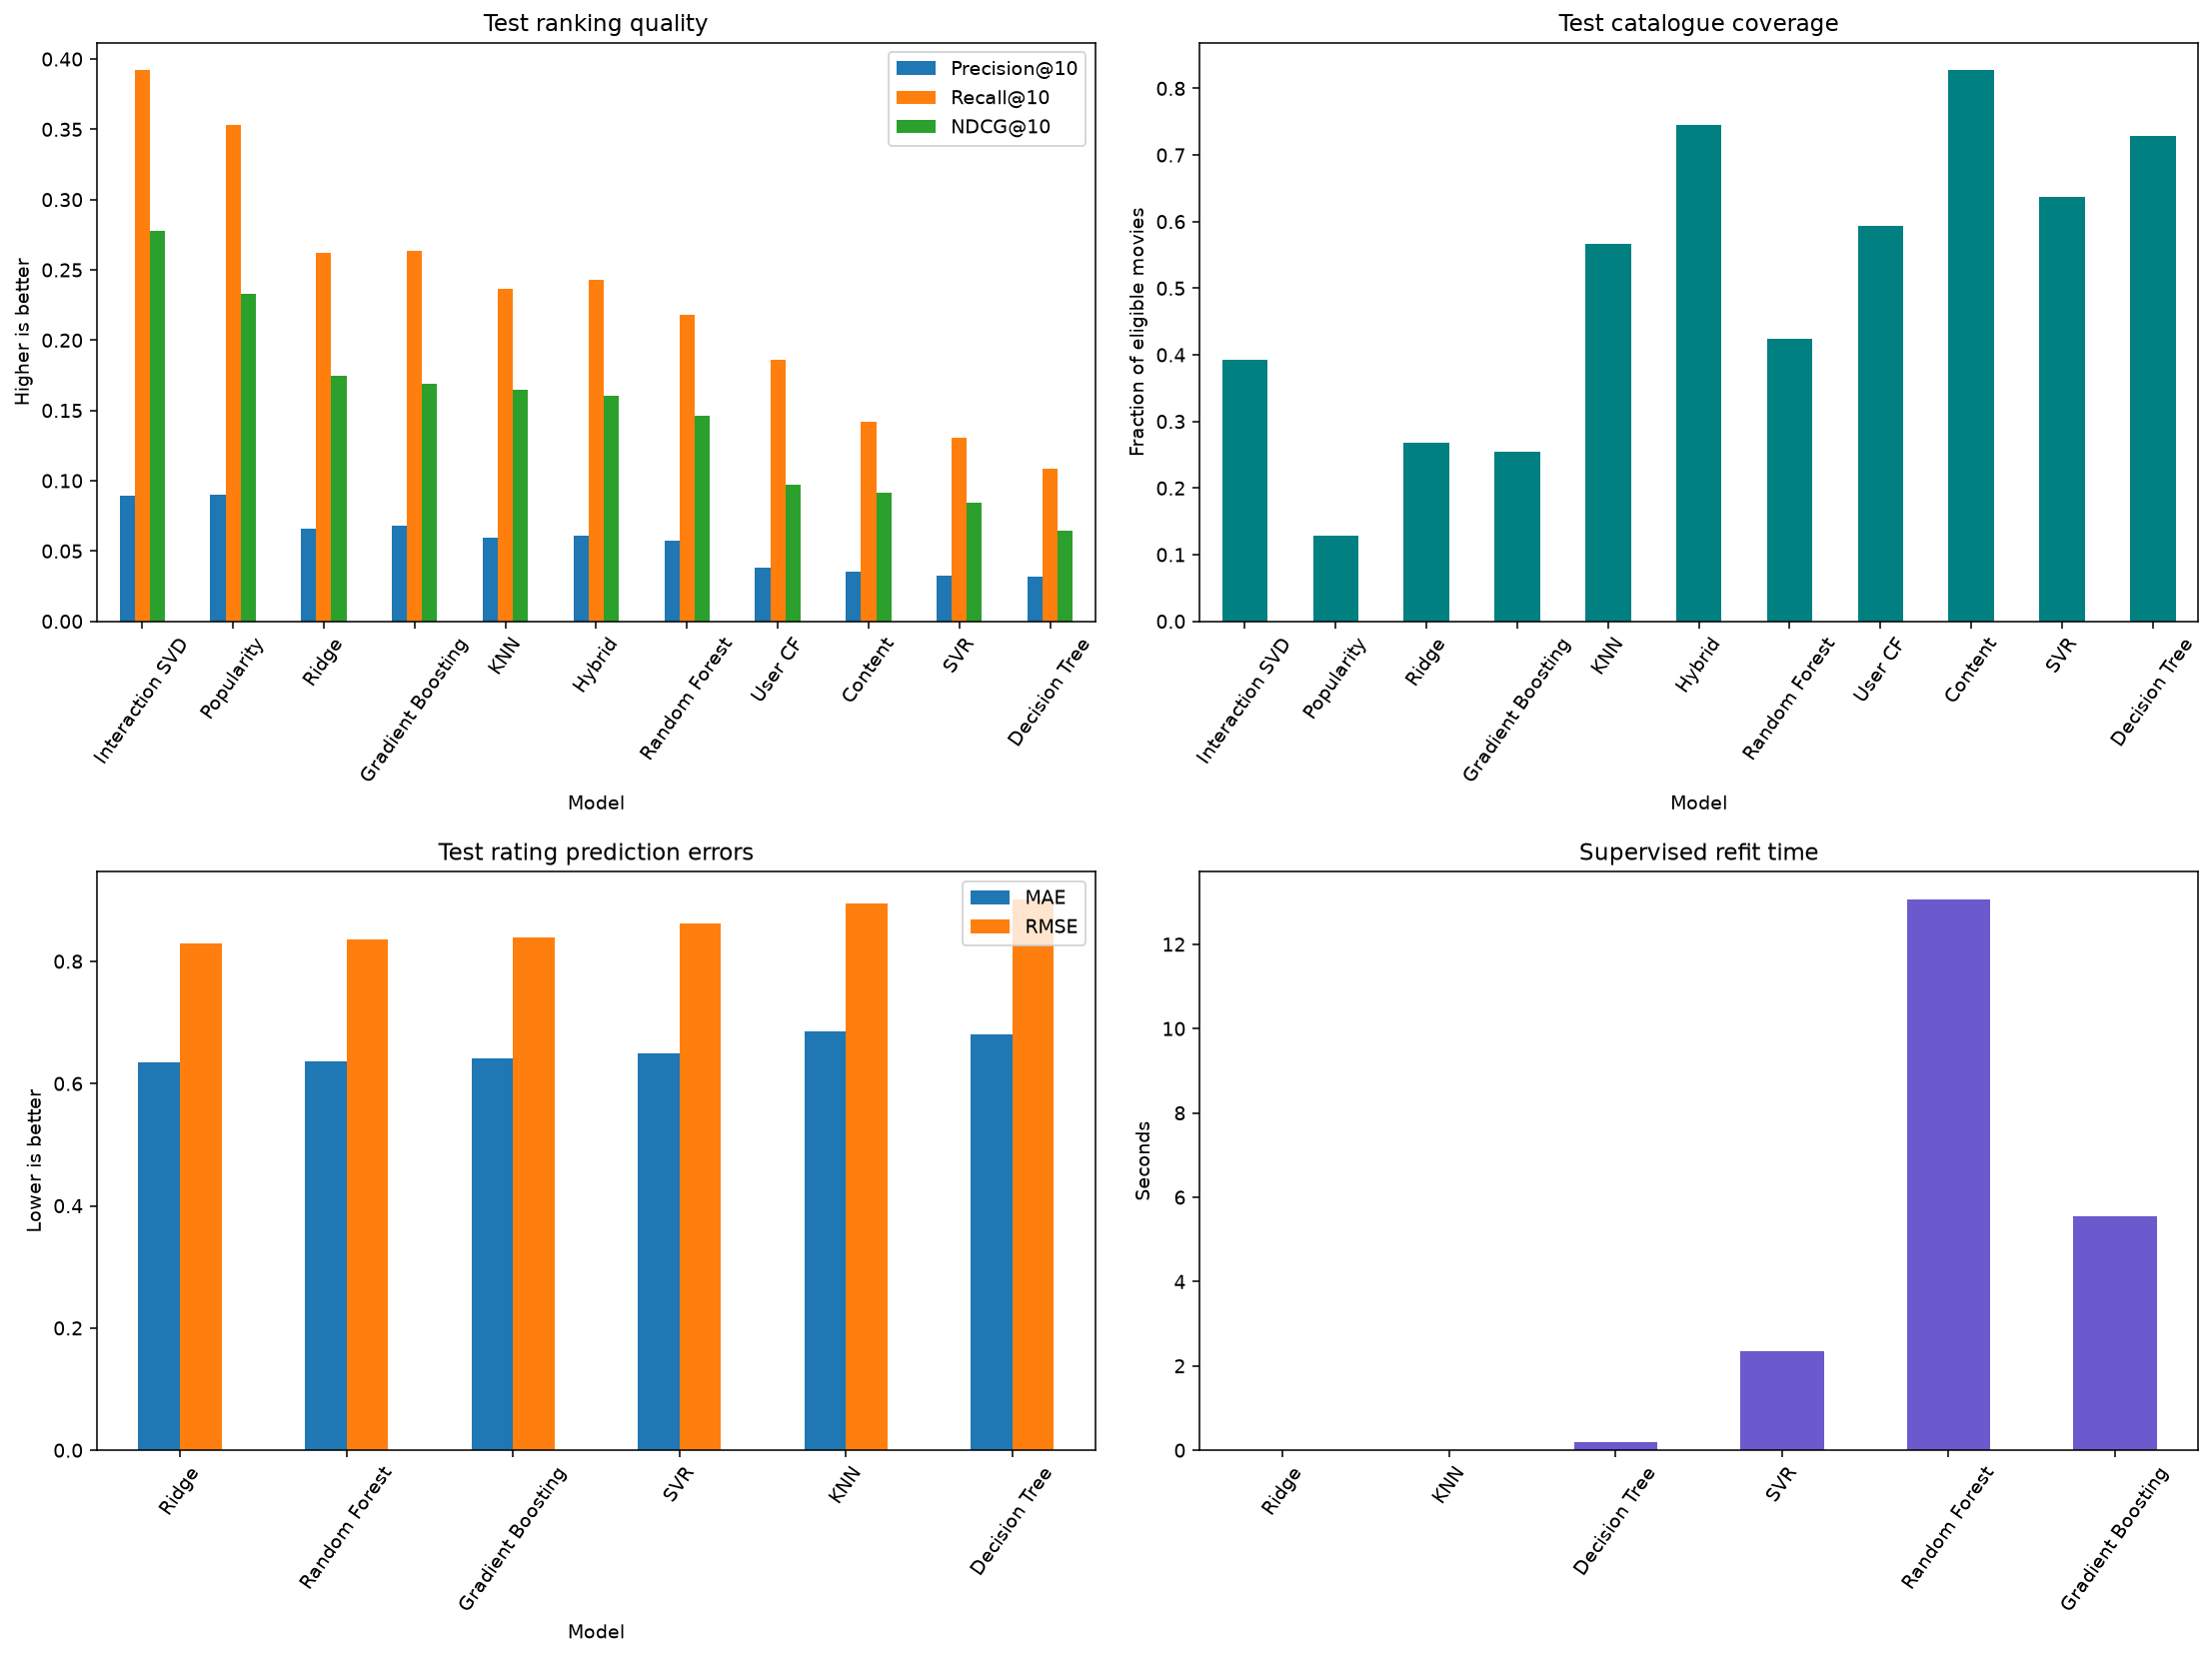

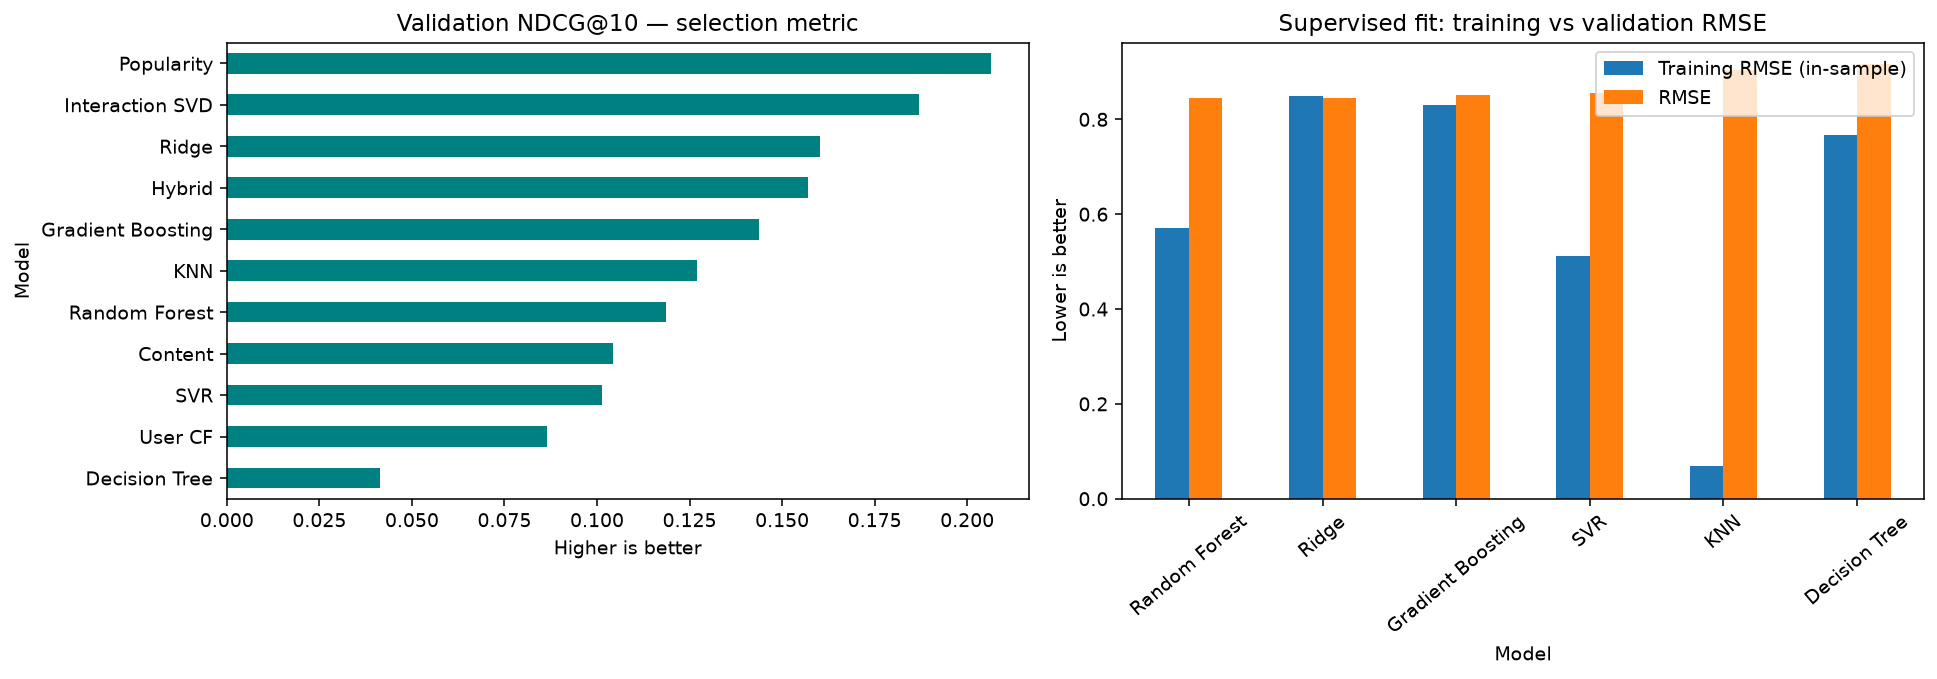

In [3]:
display(pd.read_csv(ROOT/'evaluation/validation_ranking_metrics.csv').round(4))
display(pd.read_csv(ROOT/'evaluation/test_ranking_metrics.csv').round(4))
display(pd.read_csv(ROOT/'evaluation/test_rating_metrics.csv').round(4))
display(Image(filename=str(ROOT/'evaluation/06_test_comparison.png'),width=1000))
val_plot = ROOT/'evaluation/05_validation_selection.png'
if val_plot.exists():
    display(Image(filename=str(val_plot), width=900))


## 3.1 Picking the best model

Selection rule: highest **validation NDCG@10** (tie-break: validation Recall@10). The test set is used for final reporting. Popularity is selected overall; Ridge is the best supervised model. Interaction SVD scores highest on test, but the selection rule stays fixed on validation to avoid choosing on test data.


In [4]:
val = pd.read_csv(ROOT/'evaluation/validation_ranking_metrics.csv').set_index('Model')
tst = pd.read_csv(ROOT/'evaluation/test_ranking_metrics.csv').set_index('Model')
cmp = pd.DataFrame({'Validation NDCG@10': val['NDCG@10'], 'Test NDCG@10': tst['NDCG@10']})
cmp = cmp.loc[val.sort_values(['NDCG@10', 'Recall@10'], ascending=False, kind='stable').index]
display(cmp.round(4))
print('Best by validation:', cmp.index[0])
assert cmp.index[0] == engine.model['primary_model']


,Validation NDCG@10,Test NDCG@10
Model,,
Popularity,0.2063,0.2329
Interaction SVD,0.1870,0.2774
Ridge,0.1601,0.1745
Hybrid,0.1570,0.1605
Gradient Boosting,0.1438,0.1690
KNN,0.1271,0.1645
Random Forest,0.1186,0.1464
Content,0.1043,0.0917
SVR,0.1014,0.0844


Best by validation: Popularity


## 4 Running the selected model
The default ranks films by the fitted popularity score. It is nonpersonalized apart from filters and exclusion of already rated movies.

In [5]:
result=engine.recommend({'model':'Popularity','n':10})
display(pd.DataFrame(result['results'])[['title','genre','year','minutes','score']])
print(result['notice'])

,title,genre,year,minutes,score
0,Toy Story,Animation,1995,81,3.694672
1,Finding Nemo,Animation,2003,100,3.635496
2,Alien,Action,1979,116,3.615708
3,Aladdin,Animation,1992,90,3.600514
4,Wall-E,Animation,2008,98,3.547567
5,Up,Animation,2009,96,3.529101
6,"Monsters, Inc.",Animation,2001,92,3.523091
7,Aliens,Action,1986,137,3.513976
8,Dead Poets Society,Drama,1989,128,3.483853
9,Beauty And The Beast,Musical,1991,84,3.462747


Historical catalogue; current streaming availability is unverified.


## 5 Demonstrating personalization and filters
Ridge uses the anonymous profile history. The selected profile excludes its previously rated films.

In [6]:
personal=engine.recommend({'model':'Ridge','profile_id':'380','n':10})
display(pd.DataFrame(personal['results'])[['title','genre','score','reason']])
filtered=engine.recommend({'genre':'Comedy','max_minutes':120,'n':10})
display(pd.DataFrame(filtered['results'])[['title','genre','minutes','score']])
assert all(x['genre']=='Comedy' and x['minutes']<=120 for x in filtered['results'])

,title,genre,score,reason
0,Toy Story,Animation,4.220491,Predicted preference from your profile and mov...
1,Dead Poets Society,Drama,4.204700,Predicted preference from your profile and mov...
2,Wall-E,Animation,4.173767,Predicted preference from your profile and mov...
3,Spider-Man 2,Superhero,4.171116,Predicted preference from your profile and mov...
4,"Three Billboards Outside Ebbing, Missouri",Drama,4.158428,Predicted preference from your profile and mov...
5,Louis C.K.: Shameless,Standup Comedy,4.106842,Predicted preference from your profile and mov...
6,Ratatouille,Animation,4.072479,Predicted preference from your profile and mov...
7,The Martian,Science Fiction,4.056134,Predicted preference from your profile and mov...
8,Mary Poppins,Musical,4.050682,Predicted preference from your profile and mov...
9,X-Men: Days of Future Past,Superhero,4.037167,Predicted preference from your profile and mov...


,title,genre,minutes,score
0,Little Miss Sunshine,Comedy,102,3.326574
1,Big,Comedy,104,3.274599
2,Who Framed Roger Rabbit,Comedy,99,3.181564
3,10 Things I Hate About You,Comedy,97,2.950839
4,Sister Act,Comedy,100,2.412567
5,Night At The Museum,Comedy,108,2.296949
6,Freaky Friday,Comedy,96,2.183989
7,Father Of The Bride,Comedy,105,1.800165
8,Turner & Hooch,Comedy,99,1.776948
9,Bedtime Stories,Comedy,99,1.612277


## 6 Making a new preference profile
Choose movie IDs from the catalogue below. This is an exploratory new-user demo, separate from the warm-user evaluation.

In [7]:
catalogue=pd.DataFrame(engine.model['items'])
display(catalogue.loc[catalogue.title.str.contains('Iron Man',case=False),['id','title','year']])
new_user=engine.recommend({'model':'Ridge','ratings':{'1660000038':5,'1770000948':4},'n':10})
display(pd.DataFrame(new_user['results'])[['title','genre','score']])
assert not {'1660000038','1770000948'} & {x['id'] for x in new_user['results']}

,id,title,year
179,1660000038,Iron Man,2008
180,1660000039,Iron Man 2,2010
181,1660000042,Iron Man 3,2013


,title,genre,score
0,Guardians Of The Galaxy,Superhero,4.765894
1,Logan,Superhero,4.677996
2,The Martian,Science Fiction,4.622236
3,Louis C.K.: Shameless,Standup Comedy,4.605859
4,Dead Poets Society,Drama,4.605499
5,"Three Billboards Outside Ebbing, Missouri",Drama,4.546112
6,Louis C.K.: Oh My God,Standup Comedy,4.537429
7,Mary Poppins,Musical,4.511388
8,X-Men,Superhero,4.510179
9,Toy Story 3,Animation,4.490782


## 7 Checking the Python deployment API
Flask test requests verify the API without starting a blocking server inside the notebook.

In [8]:
from app import app
client=app.test_client()
assert client.get('/api/health').status_code==200
response=client.post('/api/recommend',json={'model':'Ridge','profile_id':'380'})
assert response.status_code==200
assert client.post('/api/recommend',json={'ratings':{'1660000038':9}}).status_code==400
personal = engine.recommend({'model':'Ridge','profile_id':'380','n':10})
assert response.json['results'][0]['id']==personal['results'][0]['id']
print('Health, inference, validation and model consistency checks passed.')
display(pd.DataFrame([json.loads((ROOT/'artifacts/python_test_results.json').read_text()),
                      json.loads((ROOT/'artifacts/javascript_test_results.json').read_text())]))

Health, inference, validation and model consistency checks passed.


,python_tests,failures,errors,passed,sklearn_score_comparisons,python_js_request_comparisons,max_absolute_error,dom_browser_tested
0,10.0,0.0,0.0,True,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,True,885.0,6.0,8.881784e-16,False


## 8 Local deployment

The Python (Flask) application starts with `python app.py` and serves the interface at **http://127.0.0.1:5000**. Dependencies are listed in `requirements-runtime.txt`. The fitted artifact is included, so inference does not require retraining.

The interface calls the Python inference API. The JavaScript scoring implementation is checked against the same fitted artifact through numerical parity tests.

## 9 Scope and limitations

- Quantitative results apply to the matched MovieLens ratings and reference-observed catalogue only.
- Popularity is nonpersonalized apart from filters and exclusion of rated movies. Ridge provides personalized recommendations.
- The catalogue contains historical listings; current streaming availability is unverified.
- The custom-profile demonstration has not received a separate cold-start evaluation. A single random split does not establish future-time performance.

Problem statement, metadata, exploratory analysis and the preprocessing pipeline are in the Phase 2 notebook and the report. This notebook covers deployment and demonstration of the selected model.

## 10 Responsible use of AI tools

AI assistance was used for code generation and correction, notebook organization, debugging, execution checks, tests and report editing. Section 10 of the report records the declaration with prompts visible in the project conversation, critical evaluation and design decisions. Each student must provide and confirm their own reflection on learning and design ownership; AI-generated reflections are not presented as personal testimony. All reported numbers come from program execution.
